In [1]:
import importlib
import dataset as dataset_module

dataset_module = importlib.reload(dataset_module)
BvhDataset = dataset_module.BvhDataset
from itertools import permutations, product
from sklearn.cluster import KMeans
from comparison_methods import fit_cluster_mapping, choose_m4_params, predict_one_level, predict_two_level, apply_per_record, evaluate, causal_majority, transition_automaton
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from constants import MAJORITY_WINDOWS, CONFIRMATION_WINDOWS, CONFIDENCE_THRESHOLDS
from catboost import CatBoostClassifier
from sammon.sammon import sammon
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.metrics import balanced_accuracy_score
from scipy.special import expit

### Иследование зависимости от оператора

In [2]:
NAMES = ['rec_4_operator_2_chr01_MAYA', 'rec_4_operator_3_chr01_MAYA',
         'rec_4_operator_4_chr01_MAYA', 'rec_4_operator_6_chr01_MAYA',
         'rec_4_operator_7_chr01_MAYA']

MAIN_JOINTS = [
    "Hips", "Spine", "Neck", "Head",
    "LeftArm", "LeftForeArm", "LeftHand",
    "RightArm", "RightForeArm", "RightHand",
]

In [3]:
val_test = list(permutations(NAMES, 2))

In [4]:
datasets = []
list_names = []

In [5]:
for i in range(len(val_test)):
    ls = [name for name in NAMES if name not in val_test[i]] + list(val_test[i])
    dataset = BvhDataset(main_joints = MAIN_JOINTS, list_names=ls, cut_target_slices = True)

    datasets.append(dataset)
    list_names.append(ls)

Классы датасета: {'DISTRACTOR': 0, 'STOP/START': 1}
Запись rec_4_operator_4_chr01_MAYA: загружена из кэша
Запись rec_4_operator_6_chr01_MAYA: загружена из кэша
Запись rec_4_operator_7_chr01_MAYA: загружена из кэша
Обработка BVH 1/1: rec_4_operator_2_chr01_MAYA
233 {'command': 'STOP/START', 'frame_start': '233', 'frame_end': '347'}
13587 {'command': 'STOP/START', 'frame_start': '13245', 'frame_end': '13587'}
Запись rec_4_operator_3_chr01_MAYA: загружена из кэша
PCA на train: (5354, 10991), float32
Классы датасета: {'DISTRACTOR': 0, 'STOP/START': 1}
Запись rec_4_operator_3_chr01_MAYA: загружена из кэша
Запись rec_4_operator_6_chr01_MAYA: загружена из кэша
Запись rec_4_operator_7_chr01_MAYA: загружена из кэша
Запись rec_4_operator_2_chr01_MAYA: загружена из кэша
Запись rec_4_operator_4_chr01_MAYA: загружена из кэша
PCA на train: (5467, 10991), float32
Классы датасета: {'DISTRACTOR': 0, 'STOP/START': 1}
Запись rec_4_operator_3_chr01_MAYA: загружена из кэша
Запись rec_4_operator_4_chr01_MAY

In [6]:
def load_split(df):
    meta_columns = ['record_id', 'window_start_frame', 'window_end_frame']
    pc_columns = [c for c in df.columns if c.startswith('pc')]

    return df[pc_columns].to_numpy(float), df['target'].to_numpy(int), df[meta_columns].copy()

def record_slices(meta):
    ids = meta['record_id'].to_numpy()
    if len(ids) == 0:
        raise ValueError('Выборка не содержит окон')
    starts = np.r_[0, np.flatnonzero(ids[1:] != ids[:-1]) + 1]
    stops = np.r_[starts[1:], len(ids)]

    slices = [slice(start, stop) for start, stop in zip(starts, stops)]
    return slices, [sl.stop - sl.start for sl in slices]

In [7]:
N_ACTION_PROTOTYPES = 2
N_SUBACTION_PROTOTYPES = 4
RANDOM_STATE = 42

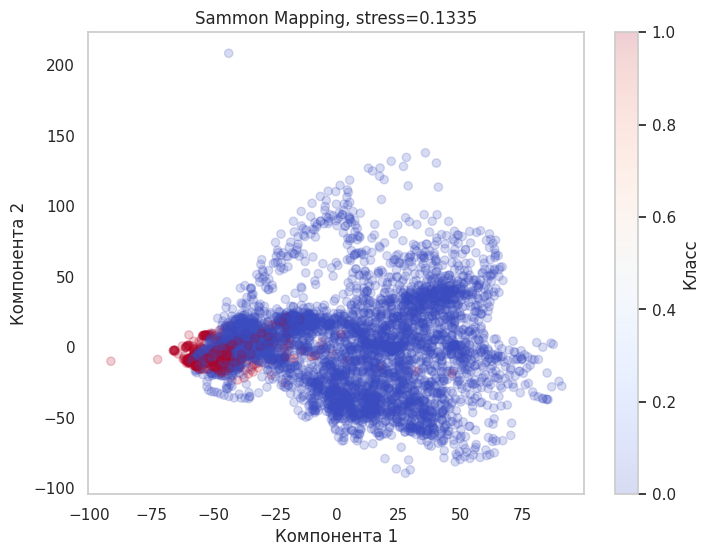

In [8]:
train_df, conf_df, test_df = datasets[0].get_datasets()
X_train, y_train, train_meta = load_split(train_df)
X_conf, y_conf, conf_meta = load_split(conf_df)
X_test, y_test, test_meta = load_split(test_df)

Z, stress = sammon(X_train, n=2, maxiter=1)

plt.figure(figsize=(8, 6))
plt.scatter(Z[:, 0], Z[:, 1], c=y_train, cmap="coolwarm", alpha=0.2)
plt.colorbar(label="Класс")
plt.title(f"Sammon Mapping, stress={stress:.4f}")
plt.xlabel("Компонента 1")
plt.ylabel("Компонента 2")
plt.grid()
plt.show()

In [9]:
def pipeline2(X_train, y_train, X_conf, y_conf, X_test, y_test,
              conf_slices, test_slices, *, train_slices):
    metric_params = {'active_command_ids': (1,)}
    fsm_params = {
        'neutral_id': 0, 'distractor_id': 0,
        'label_names': {0: 'DISTRACTOR', 1: 'STOP/START'},
    }

    candidates = [
        ('LogReg', f'C={c}', LogisticRegression(
            C=c, class_weight='balanced', max_iter=2000, random_state=RANDOM_STATE,
        ))
        for c in (0.1, 1.0)
    ]
    candidates += [
        ('SVM', f'C={c}', SVC(C=c, gamma='scale', class_weight='balanced'))
        for c in (1.0, 10.0)
    ]
    candidates += [
        ('CatBoost', f'iterations={iterations}, depth={depth}, lr={lr}', CatBoostClassifier(
            iterations=iterations, depth=depth, learning_rate=lr,
            auto_class_weights='Balanced', loss_function='Logloss',
            random_seed=RANDOM_STATE, verbose=False, thread_count=2,
            allow_writing_files=False,
        ))
        for iterations, depth, lr in ((100, 4, 0.01), (400, 4, 0.05), (400, 6, 0.05))
    ]
    candidates += [
        ('ExtraTrees', f'min_samples_leaf={leaf}', ExtraTreesClassifier(
            n_estimators=200, min_samples_leaf=leaf, class_weight='balanced',
            random_state=RANDOM_STATE, n_jobs=2,
        ))
        for leaf in (1, 5)
    ]

    def score(model, X):
        if isinstance(model, SVC):
            return expit(model.decision_function(X))
        return model.predict_proba(X)[:, list(model.classes_).index(1)]

    def measure(y, pred, slices):
        return evaluate(y, pred, slices, **metric_params)

    def rank(row):
        delay = row['p95_delay_s']
        return (-row['event_f1@50'], row['false_activations_per_min'],
                row['double_commands_per_transition'],
                delay if np.isfinite(delay) else np.inf)

    best_models = {}
    for family, params, model in candidates:
        model.fit(X_train, y_train)
        conf_score = score(model, X_conf)
        choices = []
        for threshold in (0.3, 0.5, 0.7):
            pred = (conf_score >= threshold).astype(int)
            choices.append({
                'threshold': threshold, **measure(y_conf, pred, conf_slices),
            })
        best = min(choices, key=rank)
        if family not in best_models or rank(best) < rank(best_models[family]['best']):
            best_models[family] = {
                'model': model, 'params': params, 'score': conf_score, 'best': best,
            }

    def filter_output(values, slices, threshold, kind, window, confirmations, q):
        labels = (values >= threshold).astype(int)
        if kind == 'raw':
            return labels
        if kind == 'majority':
            return apply_per_record(
                labels, slices, lambda x: causal_majority(x, window),
            )[0]
        confidence = np.where(
            labels == 1, (values - threshold) / (1 - threshold),
            (threshold - values) / threshold,
        )
        return apply_per_record(
            labels, slices,
            lambda x, c: transition_automaton(x, c, confirmations, q, **fsm_params),
            np.clip(confidence, 0, 1),
        )[0]

    selected = []
    for family, info in best_models.items():
        threshold = info['best']['threshold']
        variants = [('raw', 1, 1, 0.0)]
        variants += [('majority', int(w), 1, 0.0) for w in MAJORITY_WINDOWS]
        variants += [
            ('FSM', 1, int(n), float(q))
            for n, q in product(CONFIRMATION_WINDOWS, CONFIDENCE_THRESHOLDS)
        ]
        choices = []
        for kind, window, confirmations, q in variants:
            pred = filter_output(info['score'], conf_slices, threshold,
                                 kind, window, confirmations, q)
            choices.append({
                'filter': kind, 'window': window, 'confirmations': confirmations, 'q': q,
                **measure(y_conf, pred, conf_slices),
            })
        for kind in ('raw', 'majority', 'FSM'):
            best = min([row for row in choices if row['filter'] == kind], key=rank)
            selected.append((family, info, best))

    rows = []
    for family, info, best in selected:
        threshold = info['best']['threshold']
        args = (threshold, best['filter'], best['window'], best['confirmations'], best['q'])
        train_pred = filter_output(score(info['model'], X_train), train_slices, *args)
        test_pred = filter_output(score(info['model'], X_test), test_slices, *args)
        rows.append({
            'method': family, 'params': info['params'],
            'filter': best['filter'], 'class_threshold': threshold,
            'window': best['window'], 'confirmations': best['confirmations'], 'q': best['q'],
            'conf_f1@50': best['event_f1@50'],
            'train_f1@50': measure(y_train, train_pred, train_slices)['event_f1@50'],
            **measure(y_test, test_pred, test_slices),
            'balanced_accuracy': balanced_accuracy_score(y_test, test_pred),
            'true_active_fraction': np.mean(y_test == 1),
            'predicted_active_fraction': np.mean(test_pred == 1),
        })

    return pd.DataFrame(rows)


In [10]:
operators = [[] for _ in NAMES]

In [11]:
for i in range(len(datasets)):
    train_df, conf_df, test_df = datasets[i].get_datasets()
    X_train, y_train, train_meta = load_split(train_df)
    X_conf, y_conf, conf_meta = load_split(conf_df)
    X_test, y_test, test_meta = load_split(test_df)

    train_slices, train_sizes = record_slices(train_meta)
    conf_slices, conf_sizes = record_slices(conf_meta)
    test_slices, test_sizes = record_slices(test_meta)


    args = (X_train, y_train, X_conf, y_conf, X_test, y_test, conf_slices, test_slices)
    comparison = pipeline2(*args, train_slices=train_slices)

    comparison['conf_operator'] = list_names[i][-2]
    comparison['test_operator'] = list_names[i][-1]

    operators[NAMES.index(list_names[i][-1])].append(comparison)

## Устойчивость к выбору валидационного оператора

In [12]:
rows = []
for name, comparisons in zip(NAMES, operators):
    for comparison in comparisons:
        table = comparison.copy()
        rows.append(table)

results = pd.concat(rows, ignore_index=True)


group_keys = ['method', 'filter', 'test_operator']
counts = results.groupby(group_keys)['conf_operator'].nunique()

metrics = ['event_f1@10', 'event_f1@50', 'false_activations_per_min', 'double_commands_per_transition']
all_metrics = [
    'frame_accuracy', 'balanced_accuracy', 'event_f1@10', 'event_f1@50', 'event_precision', 'event_recall',
    'false_activations_per_min', 'double_commands_per_transition',
    'median_delay_s', 'p95_delay_s', 'missed_commands',
]
mean_metrics = results.groupby(['method', 'filter'])[all_metrics].mean()
display(mean_metrics.round(3))

validation_stability = results.groupby(group_keys)[metrics].agg(['count', 'mean', 'std', 'min', 'max'])
for metric in metrics:
    validation_stability[(metric, 'range')] = (
        validation_stability[(metric, 'max')] - validation_stability[(metric, 'min')]
    )
validation_stability = validation_stability.reindex(
    columns=pd.MultiIndex.from_product([metrics, ['count', 'mean', 'std', 'min', 'max', 'range']])
)
for metric in metrics:
    print(metric)
    table = validation_stability[metric].rename(
        index=lambda name: name.split('operator_')[1].split('_')[0], level='test_operator',
    )
    with pd.option_context('display.max_rows', 100):
        display(table.round(3))

summary_rows = []
for (model, variant), group in validation_stability.groupby(level=['method', 'filter']):
    row = {'method': model, 'filter': variant}
    for metric in metrics:
        row[(metric, 'mean')] = group[(metric, 'mean')].mean()
        row[(metric, 'mean_conf_std')] = group[(metric, 'std')].mean()
        row[(metric, 'max_conf_range')] = group[(metric, 'range')].max()
        row[(metric, 'between_test_std')] = group[(metric, 'mean')].std()
    summary_rows.append(row)

model_stability = pd.DataFrame(summary_rows).set_index(['method', 'filter'])
model_stability.columns = pd.MultiIndex.from_tuples(model_stability.columns)
for metric in metrics:
    print(metric)
    display(model_stability[metric].round(3))

print('mean_conf_std: среднее стандартное отклонение по четырём conf при фиксированном test.')
print('max_conf_range: наибольший размах по conf среди пяти тестовых операторов.')
print('between_test_std: стандартное отклонение средних результатов между тестовыми операторами.')
print('Маленький разброс оцениваем вместе с F1: стабильно низкое качество не означает хорошую модель.')


frame_accuracy  balanced_accuracy  event_f1@10  \
method     filter                                                     
CatBoost   FSM                0.954              0.922        0.890   
           majority           0.958              0.930        0.873   
           raw                0.960              0.936        0.867   
ExtraTrees FSM                0.967              0.939        0.937   
           majority           0.970              0.946        0.932   
           raw                0.971              0.948        0.930   
LogReg     FSM                0.949              0.930        0.909   
           majority           0.960              0.950        0.889   
           raw                0.961              0.954        0.889   
SVM        FSM                0.964              0.943        0.931   
           majority           0.965              0.939        0.901   
           raw                0.965              0.943        0.897   

                     event_f1@50  event_precision  event_recall  \
method     filter                                                 
CatBoost   FSM             0.867            0.829         0.933   
           majority        0.843            0.780         0.942   
           raw             0.838            0.774         0.942   
ExtraTrees FSM             0.909            0.891         0.938   
           majority        0.909            0.878         0.950   
           raw             0.907            0.876         0.950   
LogReg     FSM             0.869            0.823         0.933   
           majority        0.881            0.819         0.971   
           raw             0.877            0.812         0.971   
SVM        FSM             0.906            0.892         0.933   
           majority        0.843            0.795         0.908   
           raw             0.835            0.783         0.908   

                     false_activations_per_min  \
method     filter                                
CatBoost   FSM                           0.932   
           majority                      1.390   
           raw                           1.509   
ExtraTrees FSM                           0.596   
           majority                      0.661   
           raw                           0.677   
LogReg     FSM                           0.961   
           majority                      1.046   
           raw                           1.081   
SVM        FSM                           0.545   
           majority                      1.158   
           raw                           1.259   

                     double_commands_per_transition  median_delay_s  \
method     filter                                                     
CatBoost   FSM                                0.038           0.095   
           majority                           0.054           0.090   
           raw                                0.054           0.042   
ExtraTrees FSM                                0.025           0.088   
           majority                           0.033           0.070   
           raw                                0.033           0.050   
LogReg     FSM                                0.004           0.098   
           majority                           0.008           0.025   
           raw                                0.008           0.005   
SVM        FSM                                0.021           0.048   
           majority                           0.071           0.045   
           raw                                0.071           0.018   

                     p95_delay_s  missed_commands  
method     filter                                  
CatBoost   FSM             0.376             0.80  
           majority        0.399             0.70  
           raw             0.339             0.70  
ExtraTrees FSM             0.294             0.75  
           majority        0.252             0.60  
           raw             

event_f1@10


count   mean    std    min    max  range
method     filter   test_operator                                          
CatBoost   FSM      2                  4  0.811  0.107  0.700  0.957  0.257
                    3                  4  0.912  0.083  0.800  1.000  0.200
                    4                  4  1.000  0.000  1.000  1.000  0.000
                    6                  4  0.935  0.061  0.857  1.000  0.143
                    7                  4  0.791  0.066  0.750  0.889  0.139
           majority 2                  4  0.820  0.152  0.621  0.957  0.336
                    3                  4  0.859  0.128  0.667  0.923  0.256
                    4                  4  1.000  0.000  1.000  1.000  0.000
                    6                  4  0.935  0.061  0.857  1.000  0.143
                    7                  4  0.750  0.019  0.727  0.774  0.047
           raw      2                  4  0.820  0.152  0.621  0.957  0.336
                    3                  4  0.832  0.182  0.558  0.923  0.365
                    4                  4  1.000  0.000  1.000  1.000  0.000
                    6                  4  0.935  0.061  0.857  1.000  0.143
                    7                  4  0.750  0.019  0.727  0.774  0.047
ExtraTrees FSM      2                  4  0.881  0.127  0.692  0.957  0.264
                    3                  4  0.989  0.022  0.957  1.000  0.043
                    4                  4  0.979  0.024  0.957  1.000  0.043
                    6                  4  1.000  0.000  1.000  1.000  0.000
                    7                  4  0.836  0.038  0.800  0.889  0.089
           majority 2                  4  0.871  0.120  0.692  0.957  0.264
                    3                  4  0.962  0.052  0.889  1.000  0.111
                    4                  4  0.990  0.020  0.960  1.000  0.040
                    6                  4  1.000  0.000  1.000  1.000  0.000
                    7                  4  0.836  0.038  0.800  0.889  0.089
           raw      2                  4  0.871  0.120  0.692  0.957  0.264
                    3                  4  0.954  0.067  0.857  1.000  0.143
                    4                  4  0.990  0.020  0.960  1.000  0.040
                    6                  4  1.000  0.000  1.000  1.000  0.000
                    7                  4  0.836  0.038  0.800  0.889  0.089
LogReg     FSM      2                  4  0.881  0.041  0.846  0.917  0.071
                    3                  4  0.900  0.056  0.828  0.960  0.132
                    4                  4  0.968  0.021  0.957  1.000  0.043
                    6                  4  0.990  0.020  0.960  1.000  0.040
                    7                  4  0.804  0.067  0.750  0.889  0.139
           majority 2                  4  0.881  0.041  0.846  0.917  0.071
                    3                  4  0.868  0.063  0.828  0.960  0.132
                    4                  4  0.969  0.021  0.957  1.000  0.043
                    6                  4  0.971  0.037  0.923  1.000  0.077
                    7                  4  0.756  0.012  0.750  0.774  0.024
           raw      2                  4  0.881  0.041  0.846  0.917  0.071
                    3                  4  0.859  0.045  0.828  0.923  0.095
                    4                  4  0.980  0.023  0.960  1.000  0.040
                    6                  4  0.971  0.037  0.923  1.000  0.077
                    7                  4  0.756  0.012  0.750  0.774  0.024
SVM        FSM      2                  4  0.921  0.103  0.769  1.000  0.231
                    3                  4  0.924  0.074  0.828  1.000  0.172
                    4                  4  0.981  0.038  0.923  1.000  0.077
                    6                  4  0.921  0.086  0.800  1.000  0.200
                    7                  4  0.907  0.033  0.857  0.923  0.066
           majority 2                  4  0.890  0.107  0.769  1.000  0.231
       

event_f1@50


count   mean    std    min    max  range
method     filter   test_operator                                          
CatBoost   FSM      2                  4  0.718  0.187  0.500  0.957  0.457
                    3                  4  0.912  0.083  0.800  1.000  0.200
                    4                  4  0.979  0.042  0.917  1.000  0.083
                    6                  4  0.935  0.061  0.857  1.000  0.143
                    7                  4  0.791  0.066  0.750  0.889  0.139
           majority 2                  4  0.691  0.255  0.345  0.957  0.612
                    3                  4  0.859  0.128  0.667  0.923  0.256
                    4                  4  0.979  0.042  0.917  1.000  0.083
                    6                  4  0.935  0.061  0.857  1.000  0.143
                    7                  4  0.750  0.019  0.727  0.774  0.047
           raw      2                  4  0.691  0.255  0.345  0.957  0.612
                    3                  4  0.832  0.182  0.558  0.923  0.365
                    4                  4  0.979  0.042  0.917  1.000  0.083
                    6                  4  0.935  0.061  0.857  1.000  0.143
                    7                  4  0.750  0.019  0.727  0.774  0.047
ExtraTrees FSM      2                  4  0.741  0.298  0.308  0.957  0.649
                    3                  4  0.989  0.022  0.957  1.000  0.043
                    4                  4  0.979  0.024  0.957  1.000  0.043
                    6                  4  1.000  0.000  1.000  1.000  0.000
                    7                  4  0.836  0.038  0.800  0.889  0.089
           majority 2                  4  0.774  0.312  0.308  0.957  0.649
                    3                  4  0.942  0.067  0.880  1.000  0.120
                    4                  4  0.990  0.020  0.960  1.000  0.040
                    6                  4  1.000  0.000  1.000  1.000  0.000
                    7                  4  0.836  0.038  0.800  0.889  0.089
           raw      2                  4  0.774  0.312  0.308  0.957  0.649
                    3                  4  0.934  0.076  0.857  1.000  0.143
                    4                  4  0.990  0.020  0.960  1.000  0.040
                    6                  4  1.000  0.000  1.000  1.000  0.000
                    7                  4  0.836  0.038  0.800  0.889  0.089
LogReg     FSM      2                  4  0.798  0.088  0.667  0.846  0.179
                    3                  4  0.900  0.056  0.828  0.960  0.132
                    4                  4  0.947  0.055  0.870  1.000  0.130
                    6                  4  0.969  0.040  0.917  1.000  0.083
                    7                  4  0.730  0.099  0.593  0.828  0.235
           majority 2                  4  0.881  0.041  0.846  0.917  0.071
                    3                  4  0.868  0.063  0.828  0.960  0.132
                    4                  4  0.947  0.055  0.870  1.000  0.130
                    6                  4  0.952  0.073  0.846  1.000  0.154
                    7                  4  0.756  0.012  0.750  0.774  0.024
           raw      2                  4  0.881  0.041  0.846  0.917  0.071
                    3                  4  0.859  0.045  0.828  0.923  0.095
                    4                  4  0.938  0.072  0.833  1.000  0.167
                    6                  4  0.952  0.073  0.846  1.000  0.154
                    7                  4  0.756  0.012  0.750  0.774  0.024
SVM        FSM      2                  4  0.859  0.117  0.692  0.957  0.264
                    3                  4  0.924  0.074  0.828  1.000  0.172
                    4                  4  0.941  0.074  0.846  1.000  0.154
                    6                  4  0.902  0.094  0.800  1.000  0.200
                    7                  4  0.907  0.033  0.857  0.923  0.066
           majority 2                  4  0.808  0.150  0.667  0.957  0.290
       

false_activations_per_min


... (8 outputs left out)

mean  mean_conf_std  max_conf_range  between_test_std
method     filter                                                          
CatBoost   FSM       0.932          0.688           2.442             0.764
           majority  1.390          0.955           4.885             1.063
           raw       1.509          1.191           5.750             1.113
ExtraTrees FSM       0.596          0.492           4.071             0.781
           majority  0.661          0.603           4.071             0.699
           raw       0.677          0.631           4.071             0.693
LogReg     FSM       0.961          0.354           1.353             0.886
           majority  1.046          0.382           1.353             0.938
           raw       1.081          0.372           1.015             0.926
SVM        FSM       0.545          0.600           2.035             0.219
           majority  1.158          1.081           6.077             0.677
           raw       1.259          1.122           6.077             0.765

double_commands_per_transition


mean  mean_conf_std  max_conf_range  between_test_std
method     filter                                                          
CatBoost   FSM       0.038          0.054           0.333             0.056
           majority  0.054          0.054           0.333             0.075
           raw       0.054          0.054           0.333             0.075
ExtraTrees FSM       0.025          0.040           0.417             0.056
           majority  0.033          0.045           0.417             0.064
           raw       0.033          0.045           0.417             0.064
LogReg     FSM       0.004          0.008           0.083             0.009
           majority  0.008          0.017           0.167             0.019
           raw       0.008          0.017           0.167             0.019
SVM        FSM       0.021          0.042           0.167             0.021
           majority  0.071          0.117           0.750             0.083
           raw       0.071          0.117           0.750             0.083

mean_conf_std: среднее стандартное отклонение по четырём conf при фиксированном test.
max_conf_range: наибольший размах по conf среди пяти тестовых операторов.
between_test_std: стандартное отклонение средних результатов между тестовыми операторами.
Маленький разброс оцениваем вместе с F1: стабильно низкое качество не означает хорошую модель.


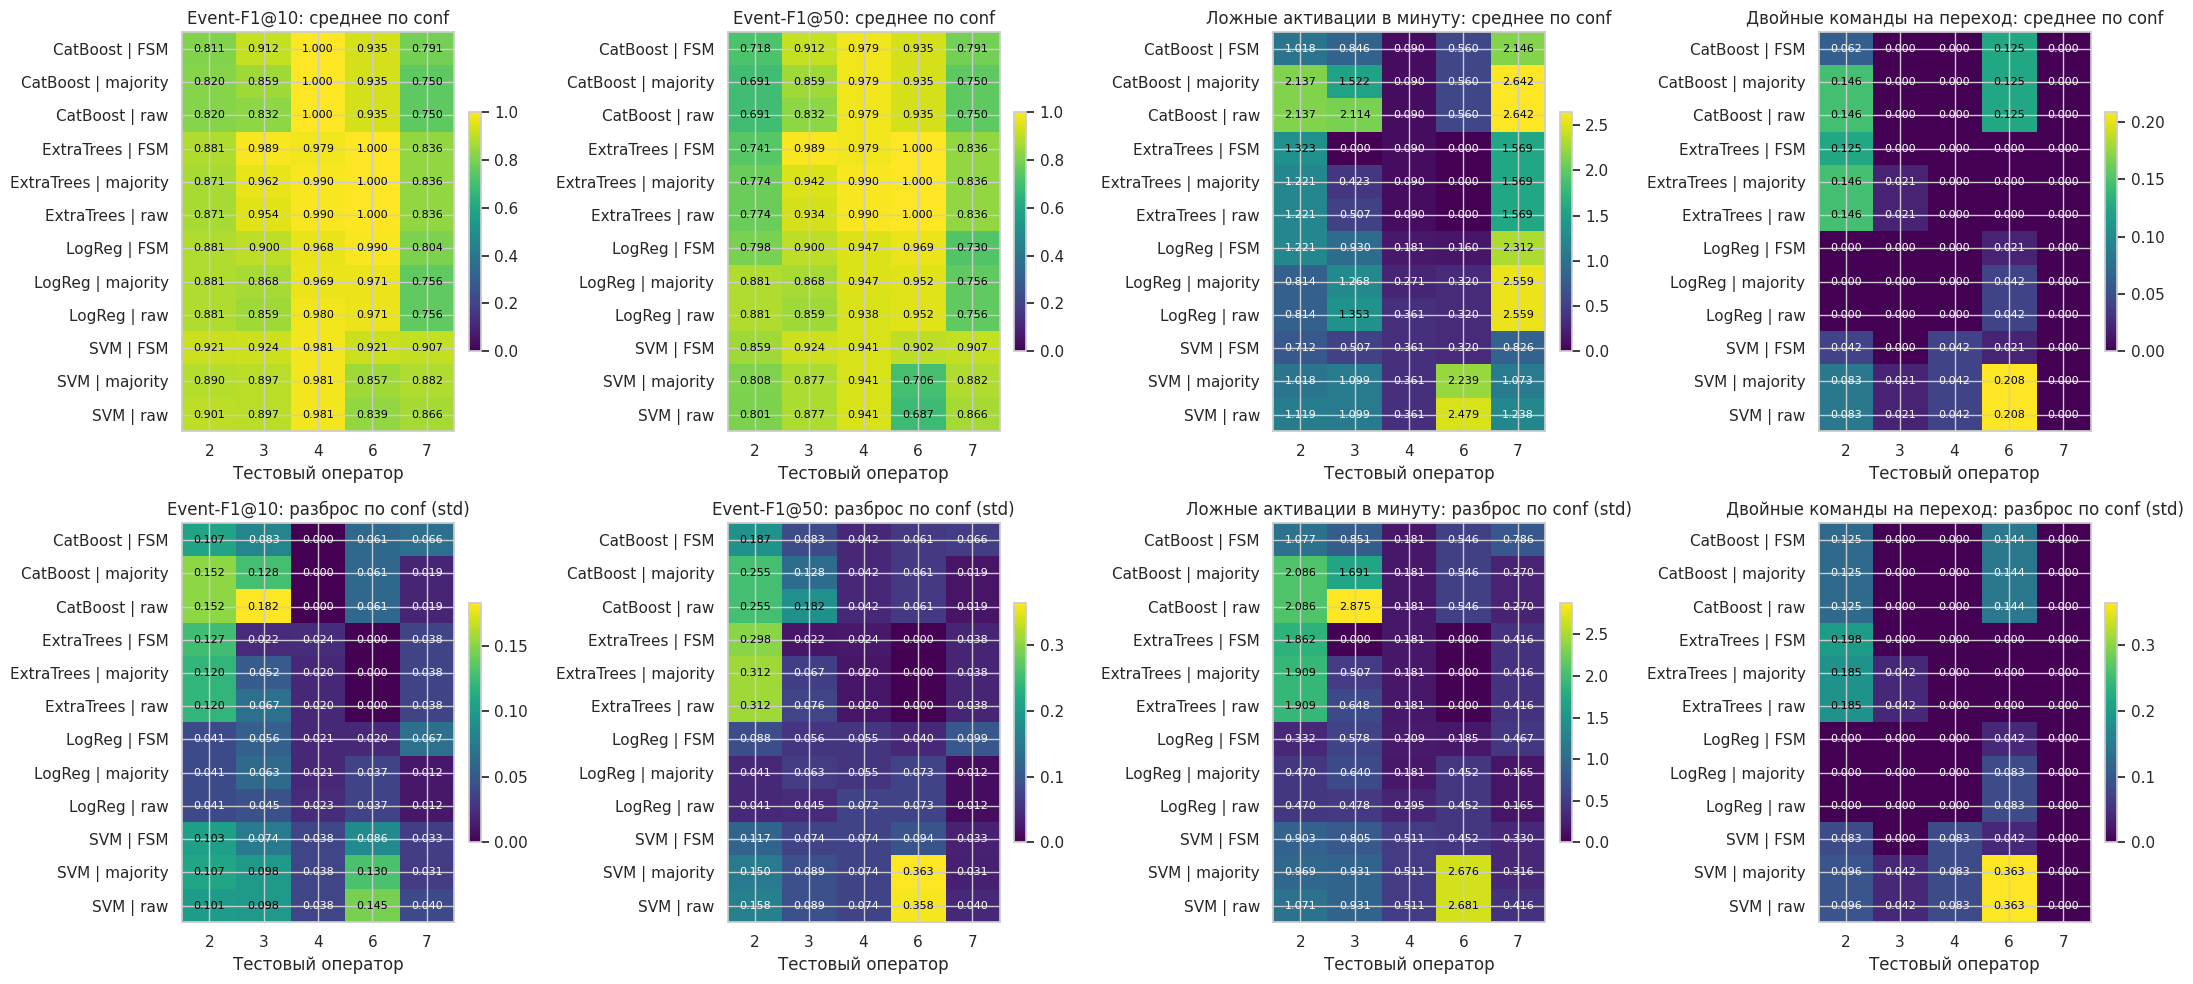

In [13]:
fig, axes = plt.subplots(2, 4, figsize=(22, 10))
titles = ['Event-F1@10', 'Event-F1@50', 'Ложные активации в минуту', 'Двойные команды на переход']
for column, (metric, title) in enumerate(zip(metrics, titles)):
    for row, statistic in enumerate(['mean', 'std']):
        table = validation_stability[(metric, statistic)].unstack('test_operator')
        ax = axes[row, column]
        image = ax.imshow(table.to_numpy(), aspect='auto', cmap='viridis', vmin=0)
        ax.set_xticks(range(len(table.columns)),
                      [name.split('operator_')[1].split('_')[0] for name in table.columns])
        ax.set_yticks(range(len(table.index)),
                      [f'{model} | {variant}' for model, variant in table.index])
        ax.set_xlabel('Тестовый оператор')
        ax.set_title(f'{title}: ' + ('среднее по conf' if statistic == 'mean' else 'разброс по conf (std)'))
        for y in range(len(table.index)):
            for x in range(len(table.columns)):
                value = table.iloc[y, x]
                midpoint = (image.norm.vmin + image.norm.vmax) / 2
                ax.text(x, y, f'{value:.3f}', ha='center', va='center', fontsize=8,
                        color='white' if value <= midpoint else 'black')
        fig.colorbar(image, ax=ax, fraction=0.04)
plt.tight_layout()
plt.show()


### Иследование зависимости от одеваний и калибровки.

In [14]:
NAMES = [['rec_5_2_1_chr01_MAYA', 'rec_5_2_2_chr01_MAYA', 'rec_5_2_3_chr01_MAYA'],
         ['rec_5_3_1_chr01_MAYA', 'rec_5_3_2_chr01_MAYA', 'rec_5_3_3_chr01_MAYA'],
         ['rec_5_4_1_chr01_MAYA', 'rec_5_4_2_chr01_MAYA', 'rec_5_4_3_chr01_MAYA']]

In [15]:
NAMES_BY_CLASS = {
    f'class_{i}': names
    for i, names in enumerate(NAMES)
}

In [16]:
from itertools import combinations

CONF_NAME = 'rec_4_operator_2_chr01_MAYA'

within_splits  = []
between_splits = []

for c, names in NAMES_BY_CLASS.items():
    for test in names:
        train = [n for n in names if n != test]
        within_splits.append((tuple(train), test, c, c))

for c_tr, tr_names in NAMES_BY_CLASS.items():
    for c_te, te_names in NAMES_BY_CLASS.items():
        if c_tr == c_te:
            continue
        for test in te_names:
            for pair in combinations(tr_names, 2):
                between_splits.append((pair, test, c_tr, c_te))

print(f"within: {len(within_splits)}, between: {len(between_splits)}")

within: 9, between: 54


In [17]:
def run_split(train_names, test_name):
    ls = list(train_names) + [CONF_NAME, test_name]
    ds = BvhDataset(main_joints=MAIN_JOINTS,
                    train_val_test_div=[len(train_names), 1, 1],
                    list_names=ls, cut_target_slices=True)
    tr_df, cf_df, te_df = ds.get_datasets()
    X_tr, y_tr, m_tr = load_split(tr_df)
    X_cf, y_cf, m_cf = load_split(cf_df)
    X_ts, y_ts, m_ts = load_split(te_df)
    tr_sl, _ = record_slices(m_tr)
    cf_sl, _ = record_slices(m_cf)
    ts_sl, _ = record_slices(m_ts)
    return pipeline2(X_tr, y_tr, X_cf, y_cf, X_ts, y_ts,
                     cf_sl, ts_sl, train_slices=tr_sl)

rows = []
for regime, splits in [('within', within_splits), ('between', between_splits)]:
    for train_pair, test, c_tr, c_te in splits:
        df = run_split(train_pair, test)
        df['regime']       = regime
        df['train_class']  = c_tr
        df['test_class']   = c_te
        df['test_recording'] = test
        df['train_recordings'] = '|'.join(train_pair)
        rows.append(df)

all_splits = pd.concat(rows, ignore_index=True)

Классы датасета: {'DISTRACTOR': 0, 'STOP/START': 1}
Запись rec_5_2_2_chr01_MAYA: загружена из кэша
Запись rec_5_2_3_chr01_MAYA: загружена из кэша
Обработка BVH 1/1: rec_4_operator_2_chr01_MAYA
233 {'command': 'STOP/START', 'frame_start': '233', 'frame_end': '347'}
16321 {'command': 'STOP/START', 'frame_start': '16035', 'frame_end': '16321'}
Запись rec_5_2_1_chr01_MAYA: загружена из кэша
PCA на train: (3014, 10991), float32
Классы датасета: {'DISTRACTOR': 0, 'STOP/START': 1}
Запись rec_5_2_1_chr01_MAYA: загружена из кэша
Запись rec_5_2_3_chr01_MAYA: загружена из кэша
Запись rec_4_operator_2_chr01_MAYA: загружена из кэша
Запись rec_5_2_2_chr01_MAYA: загружена из кэша
PCA на train: (3015, 10991), float32
Классы датасета: {'DISTRACTOR': 0, 'STOP/START': 1}
Запись rec_5_2_1_chr01_MAYA: загружена из кэша
Запись rec_5_2_2_chr01_MAYA: загружена из кэша
Запись rec_4_operator_2_chr01_MAYA: загружена из кэша
Запись rec_5_2_3_chr01_MAYA: загружена из кэша
PCA на train: (3055, 10991), float32
Класс

In [18]:
import numpy as np

metrics = ['event_f1@10', 'event_f1@50',
           'false_activations_per_min', 'double_commands_per_transition']

keys = ['method', 'filter', 'regime']

mean_tbl = all_splits.groupby(keys)[metrics].mean()
var_tbl  = all_splits.groupby(keys)[metrics].var()
std_tbl  = all_splits.groupby(keys)[metrics].std()
n_tbl    = all_splits.groupby(keys)[metrics].count()

print("Средние")
display(mean_tbl.round(3))
print("Дисперсии (var)")
display(var_tbl.round(4))
print("N сплитов")
display(n_tbl)

# Сводка: mean/var в двух режимах рядом + отношение
summary = pd.concat(
    {'mean': mean_tbl, 'var': var_tbl, 'std': std_tbl},
    axis=1, names=['stat']).unstack('regime')
summary.columns.names = ['stat', 'metric', 'regime']
display(summary.round(3))

# --- БЕЗОПАСНОЕ ДЕЛЕНИЕ ДИСПЕРСИЙ ---
var_within = var_tbl.xs('within', level='regime')
var_between = var_tbl.xs('between', level='regime')

# Заменяем нули на NaN, чтобы избежать деления на ноль и inf
ratio_var = var_between / var_within.replace(0, np.nan)

# Обрабатываем результаты:
# 1. Где была бесконечность (деление на 0) - ставим 999 (или можно np.nan)
# 2. Где остался NaN (оба нуля) - ставим 1.0 (дисперсии равны)
ratio_var = ratio_var.replace([np.inf, -np.inf], 999.0)
ratio_var = ratio_var.fillna(1.0)

print("\nvar_between / var_within (>1 = класс чувствителен, 999 = класс добавил шум там, где его не было)")
display(ratio_var.round(2))

# dF1: насколько падает качество при переходе в другой класс
delta_f1 = (mean_tbl.xs('within', level='regime')
            - mean_tbl.xs('between', level='regime'))

print("\nF1_drop = mean_within - mean_between")
display(delta_f1.round(3))

Средние


event_f1@10  event_f1@50  \
method     filter   regime                              
CatBoost   FSM      between        1.000        0.999   
                    within         1.000        1.000   
           majority between        0.997        0.996   
                    within         1.000        1.000   
           raw      between        0.997        0.996   
                    within         1.000        1.000   
ExtraTrees FSM      between        1.000        1.000   
                    within         1.000        1.000   
           majority between        1.000        1.000   
                    within         1.000        1.000   
           raw      between        1.000        1.000   
                    within         1.000        1.000   
LogReg     FSM      between        0.997        0.997   
                    within         0.992        0.992   
           majority between        0.997        0.994   
                    within         0.989        0.989   
           raw      between        0.991        0.989   
                    within         0.978        0.978   
SVM        FSM      between        0.999        0.999   
                    within         0.996        0.996   
           majority between        0.998        0.998   
                    within         0.982        0.982   
           raw      between        0.993        0.993   
                    within         0.979        0.979   

                             false_activations_per_min  \
method     filter   regime                               
CatBoost   FSM      between                      0.007   
                    within                       0.000   
           majority between                      0.037   
                    within                       0.000   
           raw      between                      0.037   
                    within                       0.000   
ExtraTrees FSM      between                      0.000   
                    within                       0.000   
           majority between                      0.000   
                    within                       0.000   
           raw      between                      0.000   
                    within                       0.000   
LogReg     FSM      between                      0.021   
                    within                       0.088   
           majority between                      0.051   
                    within                       0.131   
           raw      between                      0.116   
                    within                       0.265   
SVM        FSM      between                      0.007   
                    within                       0.043   
           majority between                      0.023   
                    within                       0.216   
           raw      between                      0.090   
                    within                       0.259   

                             double_commands_per_transition  
method     filter   regime                                   
CatBoost   FSM      between                             0.0  
                    within                              0.0  
           majority between                             0.0  
                    within                              0.0  
           raw      between                             0.0  
                    within                              0.0  
ExtraTrees FSM      between                             0.0  
                    within                              0.0  
           majority between                             0.0  
                    within                              0.0  
           raw      between                             0.0  
                    within                              0.0  
LogReg     FSM      between                             0.0  
                    within                              0.0  
           majority between                  

Дисперсии (var)


event_f1@10  event_f1@50  \
method     filter   regime                              
CatBoost   FSM      between       0.0000       0.0001   
                    within        0.0000       0.0000   
           majority between       0.0001       0.0002   
                    within        0.0000       0.0000   
           raw      between       0.0001       0.0002   
                    within        0.0000       0.0000   
ExtraTrees FSM      between       0.0000       0.0000   
                    within        0.0000       0.0000   
           majority between       0.0000       0.0000   
                    within        0.0000       0.0000   
           raw      between       0.0000       0.0000   
                    within        0.0000       0.0000   
LogReg     FSM      between       0.0001       0.0001   
                    within        0.0002       0.0002   
           majority between       0.0001       0.0003   
                    within        0.0003       0.0003   
           raw      between       0.0005       0.0006   
                    within        0.0017       0.0017   
SVM        FSM      between       0.0000       0.0000   
                    within        0.0001       0.0001   
           majority between       0.0001       0.0001   
                    within        0.0017       0.0017   
           raw      between       0.0004       0.0004   
                    within        0.0025       0.0025   

                             false_activations_per_min  \
method     filter   regime                               
CatBoost   FSM      between                     0.0029   
                    within                      0.0000   
           majority between                     0.0192   
                    within                      0.0000   
           raw      between                     0.0192   
                    within                      0.0000   
ExtraTrees FSM      between                     0.0000   
                    within                      0.0000   
           majority between                     0.0000   
                    within                      0.0000   
           raw      between                     0.0000   
                    within                      0.0000   
LogReg     FSM      between                     0.0136   
                    within                      0.0305   
           majority between                     0.0232   
                    within                      0.0386   
           raw      between                     0.0715   
                    within                      0.2839   
SVM        FSM      between                     0.0029   
                    within                      0.0166   
           majority between                     0.0090   
                    within                      0.2687   
           raw      between                     0.0530   
                    within                      0.4157   

                             double_commands_per_transition  
method     filter   regime                                   
CatBoost   FSM      between                             0.0  
                    within                              0.0  
           majority between                             0.0  
                    within                              0.0  
           raw      between                             0.0  
                    within                              0.0  
ExtraTrees FSM      between                             0.0  
                    within                              0.0  
           majority between                             0.0  
                    within                              0.0  
           raw      between                             0.0  
                    within                              0.0  
LogReg     FSM      between                             0.0  
                    within                              0.0  
           majority between                  

N сплитов


event_f1@10  event_f1@50  \
method     filter   regime                              
CatBoost   FSM      between           54           54   
                    within             9            9   
           majority between           54           54   
                    within             9            9   
           raw      between           54           54   
                    within             9            9   
ExtraTrees FSM      between           54           54   
                    within             9            9   
           majority between           54           54   
                    within             9            9   
           raw      between           54           54   
                    within             9            9   
LogReg     FSM      between           54           54   
                    within             9            9   
           majority between           54           54   
                    within             9            9   
           raw      between           54           54   
                    within             9            9   
SVM        FSM      between           54           54   
                    within             9            9   
           majority between           54           54   
                    within             9            9   
           raw      between           54           54   
                    within             9            9   

                             false_activations_per_min  \
method     filter   regime                               
CatBoost   FSM      between                         54   
                    within                           9   
           majority between                         54   
                    within                           9   
           raw      between                         54   
                    within                           9   
ExtraTrees FSM      between                         54   
                    within                           9   
           majority between                         54   
                    within                           9   
           raw      between                         54   
                    within                           9   
LogReg     FSM      between                         54   
                    within                           9   
           majority between                         54   
                    within                           9   
           raw      between                         54   
                    within                           9   
SVM        FSM      between                         54   
                    within                           9   
           majority between                         54   
                    within                           9   
           raw      between                         54   
                    within                           9   

                             double_commands_per_transition  
method     filter   regime                                   
CatBoost   FSM      between                              54  
                    within                                9  
           majority between                              54  
                    within                                9  
           raw      between                              54  
                    within                                9  
ExtraTrees FSM      between                              54  
                    within                                9  
           majority between                              54  
                    within                                9  
           raw      between                              54  
                    within                                9  
LogReg     FSM      between                              54  
                    within                                9  
           majority between                  

stat                       mean                            \
metric              event_f1@10        event_f1@50          
regime                  between within     between within   
method     filter                                           
CatBoost   FSM            1.000  1.000       0.999  1.000   
           majority       0.997  1.000       0.996  1.000   
           raw            0.997  1.000       0.996  1.000   
ExtraTrees FSM            1.000  1.000       1.000  1.000   
           majority       1.000  1.000       1.000  1.000   
           raw            1.000  1.000       1.000  1.000   
LogReg     FSM            0.997  0.992       0.997  0.992   
           majority       0.997  0.989       0.994  0.989   
           raw            0.991  0.978       0.989  0.978   
SVM        FSM            0.999  0.996       0.999  0.996   
           majority       0.998  0.982       0.998  0.982   
           raw            0.993  0.979       0.993  0.979   

stat                                                  \
metric              false_activations_per_min          
regime                                between within   
method     filter                                      
CatBoost   FSM                          0.007  0.000   
           majority                     0.037  0.000   
           raw                          0.037  0.000   
ExtraTrees FSM                          0.000  0.000   
           majority                     0.000  0.000   
           raw                          0.000  0.000   
LogReg     FSM                          0.021  0.088   
           majority                     0.051  0.131   
           raw                          0.116  0.265   
SVM        FSM                          0.007  0.043   
           majority                     0.023  0.216   
           raw                          0.090  0.259   

stat                                                              var         \
metric              double_commands_per_transition        event_f1@10          
regime                                     between within     between within   
method     filter                                                              
CatBoost   FSM                                 0.0    0.0       0.000  0.000   
           majority                            0.0    0.0       0.000  0.000   
           raw                                 0.0    0.0       0.000  0.000   
ExtraTrees FSM                                 0.0    0.0       0.000  0.000   
           majority                            0.0    0.0       0.000  0.000   
           raw                                 0.0    0.0       0.000  0.000   
LogReg     FSM                                 0.0    0.0       0.000  0.000   
           majority                            0.0    0.0       0.000  0.000   
           raw                                 0.0    0.0       0.001  0.002   
SVM        FSM                                 0.0    0.0       0.000  0.000   
           majority                            0.0    0.0       0.000  0.002   
           raw                                 0.0    0.0       0.000  0.003   

stat                 ...                                               std  \
metric               ... double_commands_per_transition        event_f1@10   
regime               ...                        between within     between   
method     filter    ...                                                     
CatBoost   FSM       ...                            0.0    0.0       0.000   
           majority  ...                            0.0    0.0       0.011   
           raw       ...                            0.0    0.0       0.011   
ExtraTrees FSM       ...                            0.0    0.0       0.000   
           majority  ...                            0.0    0.0       0.000   
           raw       ...                            0.0    0.0       0.000   
LogReg     FSM       ...                            0.0    0.0   


var_between / var_within (>1 = класс чувствителен, 999 = класс добавил шум там, где его не было)


event_f1@10  event_f1@50  false_activations_per_min  \
method     filter                                                          
CatBoost   FSM              1.00         1.00                       1.00   
           majority         1.00         1.00                       1.00   
           raw              1.00         1.00                       1.00   
ExtraTrees FSM              1.00         1.00                       1.00   
           majority         1.00         1.00                       1.00   
           raw              1.00         1.00                       1.00   
LogReg     FSM              0.54         0.54                       0.45   
           majority         0.47         1.04                       0.60   
           raw              0.29         0.33                       0.25   
SVM        FSM              0.17         0.17                       0.17   
           majority         0.04         0.04                       0.03   
           raw              0.14         0.14                       0.13   

                     double_commands_per_transition  
method     filter                                    
CatBoost   FSM                                  1.0  
           majority                             1.0  
           raw                                  1.0  
ExtraTrees FSM                                  1.0  
           majority                             1.0  
           raw                                  1.0  
LogReg     FSM                                  1.0  
           majority                             1.0  
           raw                                  1.0  
SVM        FSM                                  1.0  
           majority                             1.0  
           raw                                  1.0


F1_drop = mean_within - mean_between


event_f1@10  event_f1@50  false_activations_per_min  \
method     filter                                                          
CatBoost   FSM             0.000        0.001                     -0.007   
           majority        0.003        0.004                     -0.037   
           raw             0.003        0.004                     -0.037   
ExtraTrees FSM             0.000        0.000                      0.000   
           majority        0.000        0.000                      0.000   
           raw             0.000        0.000                      0.000   
LogReg     FSM            -0.005       -0.005                      0.067   
           majority       -0.008       -0.006                      0.080   
           raw            -0.012       -0.011                      0.149   
SVM        FSM            -0.003       -0.003                      0.036   
           majority       -0.016       -0.016                      0.193   
           raw            -0.013       -0.013                      0.169   

                     double_commands_per_transition  
method     filter                                    
CatBoost   FSM                                  0.0  
           majority                             0.0  
           raw                                  0.0  
ExtraTrees FSM                                  0.0  
           majority                             0.0  
           raw                                  0.0  
LogReg     FSM                                  0.0  
           majority                             0.0  
           raw                                  0.0  
SVM        FSM                                  0.0  
           majority                             0.0  
           raw                                  0.0

In [19]:
from scipy.stats import levene
import numpy as np

lev_rows = []
for (model, variant), grp in all_splits.groupby(['method', 'filter']):
    row = {'method': model, 'filter': variant}
    for m in metrics:
        w = grp.loc[grp.regime == 'within',  m].dropna()
        b = grp.loc[grp.regime == 'between', m].dropna()
        
        if len(w) >= 2 and len(b) >= 2:
            var_w = w.var()
            var_b = b.var()
            
            if var_w == 0 and var_b == 0:
                # Идеальные нули в обеих группах: дисперсии равны, разницы нет
                stat, p = 0.0, 1.0
            elif var_w == 0 or var_b == 0:
                # В одной группе нулевой разброс, в другой есть: различие критическое
                stat, p = 999.0, 0.0
            else:
                # Обычный тест Левена (Брауна-Форсайта)
                stat, p = levene(w, b, center='median')
                # Страховка от вырожденных случаев
                if np.isnan(stat) or np.isnan(p):
                    stat, p = 0.0, 1.0
                    
            row[f'{m}_W']     = stat
            row[f'{m}_pval']  = p
        else:
            # Если данных меньше 2 (такого быть не должно, но на всякий случай)
            row[f'{m}_W']     = 0.0
            row[f'{m}_pval']  = 1.0

    lev_rows.append(row)

print("Levene (Brown–Forsythe): H0 - дисперсии равны")
display(pd.DataFrame(lev_rows).set_index(['method','filter']).round(4))

Levene (Brown–Forsythe): H0 - дисперсии равны


event_f1@10_W  event_f1@10_pval  event_f1@50_W  \
method     filter                                                     
CatBoost   FSM              0.0000            1.0000       999.0000   
           majority       999.0000            0.0000       999.0000   
           raw            999.0000            0.0000       999.0000   
ExtraTrees FSM              0.0000            1.0000         0.0000   
           majority         0.0000            1.0000         0.0000   
           raw              0.0000            1.0000         0.0000   
LogReg     FSM              1.4419            0.2345         1.4419   
           majority         3.3248            0.0731         0.8137   
           raw              1.7403            0.1920         1.2701   
SVM        FSM              2.1570            0.1471         2.1570   
           majority         6.7720            0.0116         6.7720   
           raw              2.0517            0.1571         2.0517   

                     event_f1@50_pval  false_activations_per_min_W  \
method     filter                                                    
CatBoost   FSM                 0.0000                     999.0000   
           majority            0.0000                     999.0000   
           raw                 0.0000                     999.0000   
ExtraTrees FSM                 1.0000                       0.0000   
           majority            1.0000                       0.0000   
           raw                 1.0000                       0.0000   
LogReg     FSM                 0.2345                       2.1597   
           majority            0.3706                       1.9758   
           raw                 0.2642                       1.7323   
SVM        FSM                 0.1471                       2.1064   
           majority            0.0116                       6.6692   
           raw                 0.1571                       2.2001   

                     false_activations_per_min_pval  \
method     filter                                     
CatBoost   FSM                               0.0000   
           majority                          0.0000   
           raw                               0.0000   
ExtraTrees FSM                               1.0000   
           majority                          1.0000   
           raw                               1.0000   
LogReg     FSM                               0.1468   
           majority                          0.1649   
           raw                               0.1930   
SVM        FSM                               0.1518   
           majority                          0.0122   
           raw                               0.1432   

                     double_commands_per_transition_W  \
method     filter                                       
CatBoost   FSM                                    0.0   
           majority                               0.0   
           raw                                    0.0   
ExtraTrees FSM                                    0.0   
           majority                               0.0   
           raw                                    0.0   
LogReg     FSM                                    0.0   
           majority                               0.0   
           raw                                    0.0   
SVM        FSM                                    0.0   
           majority                               0.0   
           raw                                    0.0   

                     double_commands_per_transition_pval  
method     filter                                         
CatBoost   FSM                                       1.0  
           majority                                  1.0  
           raw                                       1.0  
ExtraTrees FSM                                       1.0  
           majority                                  1.0  
           raw                                       1.0  
Log

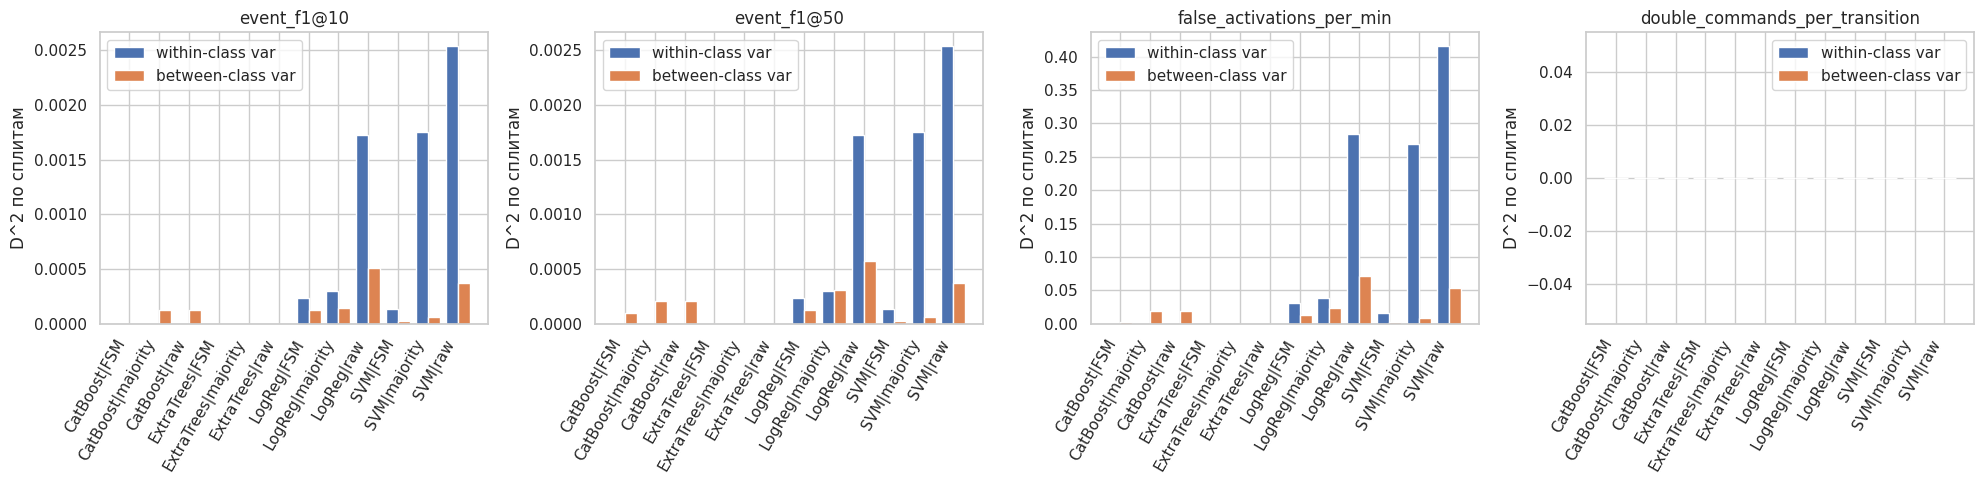

In [20]:
fig, axes = plt.subplots(1, len(metrics), figsize=(5*len(metrics), 5))
for ax, m in zip(axes, metrics):
    w = var_tbl.xs('within',  level='regime')[m]
    b = var_tbl.xs('between', level='regime')[m]
    idx = np.arange(len(w))
    ax.bar(idx - 0.2, w.values, 0.4, label='within-class var')
    ax.bar(idx + 0.2, b.values, 0.4, label='between-class var')
    ax.set_xticks(idx)
    ax.set_xticklabels([f'{a}|{b_}' for a, b_ in w.index], rotation=60, ha='right')
    ax.set_title(m)
    ax.set_ylabel('D^2 по сплитам')
    ax.legend()
plt.tight_layout()
plt.show()